# 5 · Probar un sistema de ML

<a href="https://colab.research.google.com/github/B3njjaman/MLOps-en-Azure/blob/main/modulos/modulo-1/05_probar_un_sistema_de_ml.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"></a>

**Módulo 1 · Del notebook al código reproducible.** La lección 1 terminó con una falla que ninguna celda avisa: el 10 de febrero de 2026 el consumo de ayer llega en kWh, y el bosque entrega un pronóstico de aspecto normal. Un día que falta en la tabla pasa igual de inadvertido. Esta lección convierte esas dos fallas, y otras que aparecen en el camino, en pruebas automáticas que rechazan los datos y los modelos rotos antes de que lleguen a la decisión. Es la condición 4 de la Definición 1.6.

Las pruebas se escriben primero dentro del notebook, con pytest, para verlas pasar y fallar sobre la planta simulada. Al final de la lección se llevan a un repositorio mínimo, con la estructura habitual de un proyecto de ML en Azure, y se ejecutan como lo hará la integración continua. Con eso termina el módulo: el pipeline que dibujó la lección 1 tiene todas sus piezas.

Requisitos: numpy, pandas, scikit-learn, matplotlib y pytest. La primera celda descarga el simulador de la planta y, si falta, instala `ipytest`, que permite correr pytest desde las celdas. Las cifras del texto salen de scikit-learn 1.9 y pandas 3.1. Con otras versiones, como las de Colab, algunas cambian en el último decimal (la lección 2 explica por qué), pero las pruebas pasan y fallan igual.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import importlib.util

if not Path("planta.py").exists():  # en Colab o Kaggle; en el PC ya está junto al notebook
    urlretrieve(
        "https://raw.githubusercontent.com/B3njjaman/MLOps-en-Azure/main/modulos/modulo-1/planta.py",
        "planta.py",
    )

if importlib.util.find_spec("ipytest") is None:  # Colab no lo trae
    %pip install -q ipytest

from importlib.metadata import version

for paquete in ("numpy", "pandas", "scikit-learn", "matplotlib", "pytest", "ipytest"):
    print(paquete, version(paquete))

numpy 2.4.6
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2
pytest 9.2.0
ipytest 0.14.2


## 1. Qué se prueba en un sistema de ML

En un programa común, las pruebas revisan que el código haga lo que dice. En un sistema de ML hay dos objetos más que pueden estar rotos sin que el código lo esté: los **datos**, que cambian sin avisar, y el **modelo**, que es una función aprendida y no escrita. Los tipos de prueba siguen esa división:

| Tipo de prueba | Qué verifica | Ejemplo en la planta | Dónde se construye |
|---|---|---|---|
| Unitarias | Funciones de features, parsers y utilidades | El rezago de 7 días en un ejemplo hecho a mano | Esta lección |
| De datos | Esquema, tipos, rangos, nulos, unicidad y continuidad de fechas | Consumo entre 0 y 450 MWh; sin fechas repetidas ni días que falten | Esta lección |
| De comportamiento del modelo | Dirección esperada, rango físico y desempeño mínimo | Más producción no baja el pronóstico | Esta lección |
| Compuerta de evaluación | Métrica mínima y no peor que el modelo vigente, global y por segmento | MAE del candidato menor que el de la línea base en cada trimestre | Esta lección; en el módulo 3, dentro del pipeline |
| De integración o contrato | El endpoint acepta y devuelve el formato acordado | Una entrada con los datos del día y una salida con pronóstico y versión | Módulo 4 |
| De carga | Latencia y errores con tráfico realista | Tiempo de respuesta bajo un umbral con varias solicitudes por segundo | Módulo 5 |
| De humo posdespliegue | Que lo desplegado responde | Un pronóstico conocido contra el endpoint nuevo | Módulo 5 |

Esta lección construye las cuatro primeras filas. Para hablar de ellas con precisión conviene fijar qué es una prueba.

**Definición 5.1 (prueba).** Una prueba es un predicado $\pi$ sobre un objeto $o$, que puede ser una tabla de datos, una función de features o un modelo entrenado: $\pi(o) \in \{\text{pasa}, \text{falla}\}$.

**Observación (una prueba refuta, no demuestra).** Si $\pi(o)$ falla, $o$ tiene un defecto. Si pasa, solo se sabe que esa prueba no encontró ninguno. Por eso las pruebas se acumulan, y cada una nace de una falla que ya ocurrió. La lección 1 deja una lista de fallas, y el diagrama muestra qué prueba atrapa a cada una:

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/que-atrapa-cada-prueba.svg" alt="Dos columnas de cinco filas. En la izquierda, las fallas de la lección 1: consumo en kWh desde el 10 de febrero, falta el 10 de marzo, x(t) usa la temperatura real, get_dummies con 7 columnas y luego 1, y el modelo pierde en el tercer trimestre. En la derecha, la prueba que rechaza cada una: datos con rangos y unidades, datos con fechas seguidas, features con causalidad, features con las mismas columnas con un solo día, y compuerta por trimestre. La animación enciende una fila por paso" width="760">

**Definición 5.2 (compuerta).** Sean $c$ un modelo candidato, $m$ el modelo vigente (el campeón) y $b$ la línea base. Una compuerta es una conjunción de pruebas sobre los tres,

$$G(c, m, b) = \bigwedge_{k=1}^{K} \pi_k(c, m, b).$$

El candidato pasa si todas pasan. Si falla alguna, se rechaza y se informa cuáles fallaron.

La compuerta es la última prueba del pipeline, la que decide si un modelo pasa a producción. Las secciones 3 a 5 construyen las pruebas de datos, de features y de modelo; la sección 6, la compuerta.

## 2. pytest dentro del notebook

pytest ejecuta toda función cuyo nombre empieza con `test_`. La prueba pasa si la función termina sin error y falla si algún `assert` es falso. Un notebook no es un archivo `.py`, así que se usa `ipytest`, que corre pytest sobre las funciones definidas en las celdas. La celda que empieza con `%%ipytest -q` define las pruebas y las ejecuta; `-q` pide una salida corta.

La tabla de la planta, de 2022 a 2026, se indexa por fecha. Es la tabla limpia: lo que las pruebas esperan ver.

In [2]:
import numpy as np
import pandas as pd
import pytest
import ipytest

from planta import generar

ipytest.autoconfig(addopts=["-p", "no:cacheprovider", "--color=no"], display_columns=140)

serie = generar().set_index("fecha")  # 2022 a 2026: la tabla limpia
historia = serie[:"2025-12-31"]
serie.tail(3)

,produccion,temperatura_pronostico,temperatura,consumo
fecha,,,,
2026-12-29,3010,23.2,23.7,328.6
2026-12-30,2994,19.2,21.9,323.8
2026-12-31,2977,19.5,20.6,318.6


In [3]:
%%ipytest -q
def test_la_historia_tiene_cuatro_anios():
    assert len(historia) == 1461
    assert historia.index[0] == pd.Timestamp("2022-01-01")
    assert historia.index[-1] == pd.Timestamp("2025-12-31")

.                                                                                                                                    [100%]
1 passed in 0.01s


Una prueba tiene tres partes: un objeto, una afirmación sobre él y un mensaje para cuando la afirmación falla. Las pruebas de las secciones siguientes siguen ese patrón, con una regla más: **cada falla de la lección 1 debe tener una prueba que la atrape**, y esa prueba se ve fallar antes de confiar en que pasa.

## 3. Pruebas de datos

Los datos de la planta tienen una forma fija: cuatro columnas con su tipo, un valor por día y magnitudes físicas acotadas. Cada una de esas propiedades es una prueba. Las comprobaciones se escriben como funciones que devuelven la lista de problemas, vacía si no hay ninguno, para que la misma función sirva en una prueba y, más adelante, en un paso del pipeline.

Los rangos son límites físicos que fija quien conoce la planta, no percentiles de los datos: un rango calculado con los datos acepta justamente la falla que se quiere rechazar.

In [4]:
COLUMNAS = {"produccion": "i", "temperatura_pronostico": "f", "temperatura": "f", "consumo": "f"}  # "i" entero, "f" real
RANGOS = {  # límites físicos de la planta
    "consumo": (0.0, 450.0),  # MWh por día
    "produccion": (0.0, 4000.0),  # toneladas por día
    "temperatura": (-15.0, 45.0),  # °C
    "temperatura_pronostico": (-15.0, 45.0),  # °C
}
RAZON_MAXIMA = 4.0  # el consumo no cambia más de 4 veces entre dos días seguidos


def problemas_esquema(tabla):
    if not isinstance(tabla.index, pd.DatetimeIndex):
        return ["el índice no son fechas"]
    faltan = [c for c in COLUMNAS if c not in tabla.columns]
    if faltan:
        return [f"faltan columnas: {faltan}"]
    return [
        f"{c} es {tabla[c].dtype}, se esperaba un tipo '{tipo}'"
        for c, tipo in COLUMNAS.items()
        if tabla[c].dtype.kind != tipo
    ]


def problemas_rangos(tabla):
    problemas = []
    for columna, (minimo, maximo) in RANGOS.items():
        fuera = tabla[columna][~tabla[columna].between(minimo, maximo)]  # incluye los nulos
        if len(fuera):
            problemas.append(
                f"{columna}: {len(fuera)} valores fuera de [{minimo:g}, {maximo:g}] "
                f"(desde el {fuera.index[0]:%Y-%m-%d}: {fuera.iloc[0]:g})"
            )
    return problemas


def problemas_fechas(tabla):
    fechas = tabla.index
    problemas = []
    if fechas.has_duplicates:
        problemas.append(f"{fechas.duplicated().sum()} fechas repetidas")
    if not fechas.is_monotonic_increasing:
        problemas.append("las fechas no están en orden")
    saltos = fechas.to_series().diff().dropna()
    for fecha, salto in saltos[saltos > pd.Timedelta(days=1)].items():
        problemas.append(f"faltan {salto.days - 1} día(s) antes del {fecha:%Y-%m-%d}")
    return problemas


def problemas_unidades(tabla):
    ayer = tabla["consumo"].shift(1)
    razon = tabla["consumo"] / ayer
    cambios = razon[(razon > RAZON_MAXIMA) | (razon < 1 / RAZON_MAXIMA)]
    return [
        f"consumo: pasa de {ayer[fecha]:.1f} a {tabla.loc[fecha, 'consumo']:.1f} el {fecha:%Y-%m-%d}"
        for fecha in cambios.index
    ]


def validar(tabla):
    problemas = problemas_esquema(tabla)
    if problemas:  # sin el esquema correcto, las otras comprobaciones no tienen sentido
        return problemas
    return problemas_rangos(tabla) + problemas_fechas(tabla) + problemas_unidades(tabla)

In [5]:
razon = serie["consumo"] / serie["consumo"].shift(1)
print(f"cociente entre días seguidos: mínimo {razon.min():.2f}, máximo {razon.max():.2f}")

cociente entre días seguidos: mínimo 0.30, máximo 3.18


`problemas_unidades` mira el cociente entre el consumo de dos días seguidos. En la tabla limpia ese cociente va de 0,30 a 3,18, con las paradas de mantención en los extremos. Un cambio de unidad lo multiplica por 1000. El límite de 4 deja margen sobre lo que se ha visto y queda muy por debajo de cualquier cambio de unidad. Es una decisión de negocio que se revisa si la planta cambia.

Cada prueba es una línea sobre una comprobación. La tabla que examinan sale de la variable `TABLA`, para poder cambiarla sin reescribirlas:

In [6]:
%%ipytest -q
TABLA = serie  # la tabla limpia


@pytest.fixture
def tabla():
    return TABLA


def test_esquema(tabla):
    problemas = problemas_esquema(tabla)
    assert not problemas, problemas


def test_rangos_fisicos(tabla):
    problemas = problemas_rangos(tabla)
    assert not problemas, problemas


def test_fechas_unicas_y_seguidas(tabla):
    problemas = problemas_fechas(tabla)
    assert not problemas, problemas


def test_unidades(tabla):
    problemas = problemas_unidades(tabla)
    assert not problemas, problemas

....                                                                                                                                 [100%]
4 passed in 0.02s


Con la tabla limpia pasan las cuatro. Ahora, las dos fallas de la sección 5.4 de la lección 1. Primero, el medidor que reporta en kWh desde el 10 de febrero de 2026:

In [7]:
con_kwh = serie.copy()
con_kwh.loc["2026-02-10":, "consumo"] *= 1000  # el medidor ahora reporta kWh

TABLA = con_kwh
_ = ipytest.run("-q", "--tb=no", "-rf")

.F.F                                                                                                                                 [100%]
========================================================= short test summary info =========================================================
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_rangos_fisicos - AssertionError: ['consumo: 325 valores fuera de [0, 450] (desde el 20...
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_unidades - AssertionError: ['consumo: pasa de 294.6 a 314700.0 el 2026-02-10']
2 failed, 2 passed in 0.03s


Fallan dos pruebas, las que tenían que fallar. La de rangos ve 325 días con consumo sobre 450 MWh, el primero el 10 de febrero con 314700. La de unidades ve, ese mismo día, el salto de 294,6 a 314700. El esquema no cambió y las fechas siguen seguidas, así que esas dos pasan. Que cada prueba falle solo por su motivo ayuda a leer el diagnóstico.

Segundo, el día que falta:

In [8]:
sin_el_10_de_marzo = serie.drop(pd.Timestamp("2026-03-10"))  # se perdió un día

TABLA = sin_el_10_de_marzo
_ = ipytest.run("-q", "--tb=no", "-rf")

..F.                                                                                                                                 [100%]
========================================================= short test summary info =========================================================
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_fechas_unicas_y_seguidas - AssertionError: ['faltan 1 día(s) antes del 2026-03-11']
1 failed, 3 passed in 0.02s


Aquí falla solo la prueba de fechas. Ningún valor está fuera de rango, y por eso en la lección 1 el pronóstico del 11 de marzo salía sin queja con el consumo del 9. La función `validar` junta las cuatro comprobaciones y devuelve todos los problemas de una vez, lo que más adelante necesita el pipeline:

In [9]:
TABLA = serie
print("limpia:             ", validar(serie))
print("con kWh:            ", validar(con_kwh)[:2], "...")
print("sin el 10 de marzo: ", validar(sin_el_10_de_marzo))

limpia:              []
con kWh:             ['consumo: 325 valores fuera de [0, 450] (desde el 2026-02-10: 314700)', 'consumo: pasa de 294.6 a 314700.0 el 2026-02-10'] ...
sin el 10 de marzo:  ['faltan 1 día(s) antes del 2026-03-11']


## 4. Pruebas de features

Las features son código común y se prueban como tal, pero con una exigencia más. La Definición 1.2 pide que $x_t$ se calcule solo con datos de $\mathcal{I}_t$, y esa condición también se puede probar.

La función siguiente es una versión compacta de la que la lección 4 construye completa. Trabaja sobre una tabla indexada por fecha. Con `asfreq("D")` asegura un renglón por día: si falta un día, aparece como una fila de nulos en vez de desaparecer, y el rezago del día siguiente queda nulo en vez de tomar un día equivocado. Usa el pronóstico de temperatura, el dato que existe a las 06:00.

In [10]:
def armar_features(tabla):
    t = tabla.asfreq("D")  # un renglón por día; los días que faltan quedan como nulos
    return pd.DataFrame(
        {
            "dia_semana": t.index.day_of_week,
            "produccion": t["produccion"],
            "temperatura_pronostico": t["temperatura_pronostico"],
            "consumo_ayer": t["consumo"].shift(1),
            "consumo_semana_pasada": t["consumo"].shift(7),
        },
        index=t.index,
    )

### 4.1 Un ejemplo hecho a mano

La prueba unitaria más útil usa una tabla tan chica que la respuesta se calcula de cabeza. Son diez días desde el lunes 2 de marzo de 2026, con consumo 100, 101, ..., 109. Para el último día, el miércoles 11 de marzo, el consumo de ayer es 108 y el de hace una semana es 102.

In [11]:
def tabla_chica(dias=10):
    fechas = pd.date_range("2026-03-02", periods=dias, name="fecha")  # el 2 de marzo de 2026 es lunes
    return pd.DataFrame(
        {
            "produccion": 3000,
            "temperatura_pronostico": 15.0,
            "temperatura": 15.0,
            "consumo": 100.0 + np.arange(dias),
        },
        index=fechas,
    )

In [12]:
%%ipytest -q
def test_rezagos_a_mano():
    x = armar_features(tabla_chica()).loc["2026-03-11"]
    assert x["consumo_ayer"] == 108.0
    assert x["consumo_semana_pasada"] == 102.0
    assert x["dia_semana"] == 2  # miércoles


def test_los_primeros_siete_dias_no_tienen_rezago_semanal():
    x = armar_features(tabla_chica())
    assert x["consumo_semana_pasada"].iloc[:7].isna().all()
    assert x["consumo_semana_pasada"].iloc[7:].notna().all()


def test_un_dia_que_falta_no_desplaza_el_rezago():
    tabla = tabla_chica().drop(pd.Timestamp("2026-03-08"))  # falta el domingo 8
    x = armar_features(tabla)
    assert np.isnan(x.loc["2026-03-09", "consumo_ayer"])  # no toma el consumo del 7 como si fuera el de ayer

...                                                                                                                                  [100%]
3 passed in 0.02s


La tercera prueba es la versión de features de la segunda falla de la lección 1: con el hueco, `consumo_ayer` queda nulo en vez de tomar un día equivocado. Eso solo no basta, porque un random forest de scikit-learn acepta nulos desde la versión 1.4 y pronostica igual:

In [13]:
from sklearn.ensemble import RandomForestRegressor

In [14]:
x_con_hueco = armar_features(tabla_chica().drop(pd.Timestamp("2026-03-08"))).loc[["2026-03-09"]]
print(x_con_hueco[["consumo_ayer"]].to_string())
modelo_chico = RandomForestRegressor(n_estimators=50, random_state=0).fit(
    armar_features(serie).dropna()[:500], serie["consumo"].iloc[7:507]
)
print(f"pronóstico con consumo_ayer nulo: {modelo_chico.predict(x_con_hueco)[0]:.1f} MWh, sin error ni aviso")

            consumo_ayer
fecha                   
2026-03-09           NaN
pronóstico con consumo_ayer nulo: 276.8 MWh, sin error ni aviso


El modelo no falla: entrega un número de apariencia normal. Por eso la prueba tiene que vivir antes del modelo, en los datos y en las features. Con un hueco, `validar` rechaza la tabla (sección 3), y en el ejercicio 4 una función de pronóstico rechaza también los nulos de la entrada del día.

### 4.2 Causalidad como prueba de propiedad

Una prueba de ejemplos revisa casos que alguien pensó. La causalidad no se agota en casos: dice algo sobre todas las tablas posibles. Se puede enunciar así.

**Propiedad 5.1 (causalidad de las features).** Sean $D$ y $D'$ dos tablas que coinciden en $\mathcal{I}_t$ y difieren solo en datos que a las 06:00 del día $t$ no existen. Si $x_t$ se calcula solo con datos de $\mathcal{I}_t$, entonces $x_t(D) = x_t(D')$.

*Demostración.* Si $x_t = g(\mathcal{I}_t)$ para alguna función $g$, y $D$ y $D'$ tienen el mismo $\mathcal{I}_t$, entonces $x_t(D) = g(\mathcal{I}_t) = x_t(D')$. $\square$

El contrarrecíproco es la prueba: si alterando datos posteriores a $t$ cambia $x_t$, la feature mira el futuro. No hace falta saber cómo está escrita la función: basta con perturbar. Los datos que no están en $\mathcal{I}_t$ son el consumo $y_s$ y la temperatura real $\tau_s$ desde el día $t$ en adelante, y el pronóstico de temperatura de los días posteriores a $t$, que todavía no se publica. La producción planificada es distinta: el plan se conoce de antemano, así que $\mathcal{I}_t$ lo incluye y usarlo en $x_t$ es legítimo. Por eso la prueba no lo perturba. Se les suma ruido con una semilla fija, para que la prueba dé siempre el mismo resultado. Como toda prueba, refuta pero no demuestra: una perturbación al azar podría no tocar la dependencia indebida, por eso se repite en muchos días $t$.

In [15]:
def perturbar_desde(tabla, t, rng):
    # Copia de la tabla con ruido en lo que a las 06:00 del día t todavía no existe.
    # El plan de producción se conoce de antemano: no se toca.
    nueva = tabla.astype(float)
    desde = nueva.index >= t
    despues = nueva.index > t
    nueva.loc[desde, "consumo"] += rng.normal(0, 50, desde.sum())
    nueva.loc[desde, "temperatura"] += rng.normal(0, 5, desde.sum())
    nueva.loc[despues, "temperatura_pronostico"] += rng.normal(0, 5, despues.sum())
    return nueva


def problemas_causalidad(armar, tabla, repeticiones=25, semilla=0):
    rng = np.random.default_rng(semilla)
    X = armar(tabla)
    problemas = []
    for i in rng.choice(np.arange(8, len(X) - 1), size=repeticiones, replace=False):
        t = X.index[i]
        X_alterada = armar(perturbar_desde(tabla, t, rng))
        cambian = [
            c for c in X.columns
            if not np.array_equal(X[c].iloc[[i]].to_numpy(float), X_alterada[c].iloc[[i]].to_numpy(float), equal_nan=True)
        ]
        if cambian:
            problemas.append(f"x_t del {t:%Y-%m-%d} cambia al alterar datos posteriores: {cambian}")
    return problemas

Para ver que la prueba atrapa algo, hace falta una feature con fuga. La más común es la de la sección 5.3 de la lección 1: usar la temperatura real en vez del pronóstico.

In [16]:
def armar_features_con_fuga(tabla):
    X = armar_features(tabla)
    X["temperatura_pronostico"] = tabla.asfreq("D")["temperatura"]  # la real, que a las 06:00 no existe
    return X


con_fuga = problemas_causalidad(armar_features_con_fuga, serie)
print(f"con fuga: {len(con_fuga)} días de 25 con problemas. El primero:")
print(con_fuga[0])
print("con la función correcta:", problemas_causalidad(armar_features, serie))

con fuga: 25 días de 25 con problemas. El primero:
x_t del 2026-01-13 cambia al alterar datos posteriores: ['temperatura_pronostico']
con la función correcta: []


La función con fuga falla en los 25 días elegidos, y el mensaje dice qué columna cambió: `temperatura_pronostico`. La función correcta no falla en ninguno. Una prueba que nunca ha fallado no ha demostrado que sirva, y por eso la suite incluye también la prueba de la prueba: una que exige que la fuga sea detectada.

In [17]:
%%ipytest -q
def test_las_features_son_causales():
    problemas = problemas_causalidad(armar_features, serie)
    assert not problemas, problemas


def test_la_prueba_de_causalidad_detecta_la_fuga():
    assert problemas_causalidad(armar_features_con_fuga, serie)

..                                                                                                                                   [100%]
2 passed in 0.30s


### 4.3 Las mismas columnas con un solo día

Falta la falla del `get_dummies` de la sección 5.3 de la lección 1. A las 06:00 llega un día, y la transformación debe entregar las mismas columnas que al entrenar. La prueba es una línea, y se ve fallar con la codificación de esa lección:

In [18]:
def armar_features_con_dummies(tabla):
    return pd.get_dummies(armar_features(tabla), columns=["dia_semana"], dtype=int)


def problemas_columnas(armar):
    entrenamiento = armar(serie)
    un_dia = armar(serie["2026-01-01":"2026-01-01"])
    if list(un_dia.columns) != list(entrenamiento.columns):
        return [f"con un día salen {un_dia.shape[1]} columnas y al entrenar {entrenamiento.shape[1]}"]
    return []


print("armar_features:             ", problemas_columnas(armar_features))
print("armar_features_con_dummies: ", problemas_columnas(armar_features_con_dummies))

armar_features:              []
armar_features_con_dummies:  ['con un día salen 5 columnas y al entrenar 11']


Con la función de features correcta, un día entrega las mismas 5 columnas que el entrenamiento. Con `get_dummies`, un día entrega 5 columnas y el entrenamiento 11: una por cada uno de los siete días de la semana, más las cuatro restantes. Es la falla de la lección 1 convertida en prueba.

In [19]:
%%ipytest -q
def test_las_columnas_no_dependen_de_cuantos_dias_llegan():
    assert problemas_columnas(armar_features) == []


def test_la_prueba_de_columnas_detecta_get_dummies():
    assert problemas_columnas(armar_features_con_dummies)

..                                                                                                                                   [100%]
2 passed in 0.05s


## 5. Pruebas del modelo

Un modelo no se prueba con valores exactos, porque cambian al reentrenar. Se prueban propiedades que cualquier buen modelo de esta planta debe cumplir. Son de cuatro tipos:

1. **Le gana a la línea base** en un conjunto de prueba posterior al entrenamiento: es el contrato de la lección 1.
2. **Desempeño mínimo absoluto.** Ganarle a la línea base no basta si ambos son malos. El umbral lo fija operación: con un error medio sobre 12 MWh, el equipo prefiere no usar el pronóstico. Es una decisión de negocio, y se revisa si cambia el costo de un error.
3. **Rango físico.** Ningún pronóstico sale de los límites de la planta.
4. **Dirección esperada.** Con todo lo demás fijo, producir más no baja el consumo pronosticado, y lo sube al menos la mitad de lo que dice la física. Es la prueba de comportamiento del modelo, la versión de ML de las pruebas de *directional expectation* de CheckList.

El modelo es el random forest de la lección 1, entrenado con las features de la sección 4. Para probarlo se separa un conjunto de prueba temporal, como en la sección 5.2 de la lección 1: se entrena con 2022 a 2024 y se prueba en 2025.

In [20]:
from sklearn.ensemble import RandomForestRegressor

UMBRAL_MAE = 12.0  # MWh: lo que operación tolera


def entrenar(X, y):
    X = X.dropna()
    return RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(X, y[X.index])


def error_abs(modelo, X, y):
    return (y - modelo.predict(X)).abs()


X_todo, y_todo = armar_features(serie), serie["consumo"]
ent = X_todo.index < "2025-01-01"
prueba = (X_todo.index >= "2025-01-01") & (X_todo.index < "2026-01-01")

campeon = entrenar(X_todo[ent], y_todo)  # el modelo vigente: entrenado hasta 2024
X_2025, y_2025 = X_todo[prueba], y_todo[prueba]

e_modelo = error_abs(campeon, X_2025, y_2025)
e_base = (y_2025 - X_2025["consumo_semana_pasada"]).abs()
print(f"2025, MAE del modelo:        {e_modelo.mean():.2f} MWh")
print(f"2025, MAE de la línea base:  {e_base.mean():.2f} MWh")

2025, MAE del modelo:        8.01 MWh
2025, MAE de la línea base:  22.38 MWh


### 5.1 La dirección esperada

La producción pesa 0,07 MWh por tonelada en la Definición 1.3, así que el pronóstico debe subir con ella. Se toman 40 días de 2025, se deja fija cada una de sus features salvo la producción, y esta se hace variar entre 2200 y 3200 toneladas, el rango en que opera la planta fuera de las paradas.

In [21]:
GRILLA = np.arange(2200, 3201, 50)  # toneladas


def curvas_produccion(modelo, X, n_dias=40):
    # Pronóstico de n_dias días reales, variando solo la producción a lo largo de la grilla.
    base = X.sample(n_dias, random_state=0)
    filas = base.loc[base.index.repeat(len(GRILLA))].reset_index(drop=True)
    filas["produccion"] = np.tile(GRILLA, n_dias)
    return modelo.predict(filas).reshape(n_dias, len(GRILLA))


def caida_maxima(curva):
    # La mayor caída desde un máximo anterior: 0 si la curva nunca baja.
    return (np.maximum.accumulate(curva) - curva).max()


curvas = curvas_produccion(campeon, X_2025)
caidas = np.array([caida_maxima(c) for c in curvas])
promedio = curvas.mean(axis=0)
print(f"Días con alguna caída:          {(caidas > 0).sum()} de {len(caidas)}")
print(f"Caída máxima, mediana de días:  {np.median(caidas):.2f} MWh")
print(f"Caída máxima, peor día:         {caidas.max():.2f} MWh")
print(f"Caída de la curva promedio:     {caida_maxima(promedio):.2f} MWh")
print(f"Alza de la curva promedio:      {promedio[-1] - promedio[0]:.1f} MWh")

Días con alguna caída:          40 de 40
Caída máxima, mediana de días:  1.24 MWh
Caída máxima, peor día:         6.49 MWh
Caída de la curva promedio:     0.55 MWh
Alza de la curva promedio:      50.7 MWh


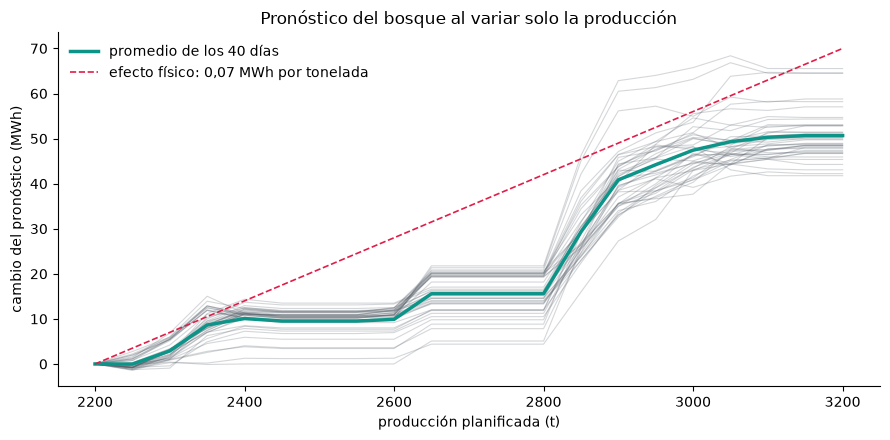

In [22]:
import matplotlib.pyplot as plt

TURQUESA, VIOLETA, AMBAR, ROSA, GRIS = "#0d9488", "#7c3aed", "#d97706", "#e11d48", "#57606a"

fig, ax = plt.subplots(figsize=(9, 4.5))
for curva in curvas:
    ax.plot(GRILLA, curva - curva[0], color=GRIS, alpha=0.25, lw=0.8)
ax.plot(GRILLA, promedio - promedio[0], color=TURQUESA, lw=2.5, label="promedio de los 40 días")
ax.plot(GRILLA, 0.07 * (GRILLA - GRILLA[0]), color=ROSA, ls="--", lw=1.2, label="efecto físico: 0,07 MWh por tonelada")
ax.set_xlabel("producción planificada (t)")
ax.set_ylabel("cambio del pronóstico (MWh)")
ax.set_title("Pronóstico del bosque al variar solo la producción")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

El bosque **viola** la dirección esperada: en los 40 días hay algún tramo donde más producción baja el pronóstico. La caída máxima es de 1,24 MWh en el día mediano y de 6,49 en el peor. No es una casualidad de esta corrida. Cada árbol parte la producción en umbrales fijados con datos ruidosos, y el promedio de árboles es una escalera irregular, sin garantía de monotonía. Exigirle una caída máxima de cero es pedirle algo que no promete. Queda decidir qué tolerancia es razonable, y hay tres criterios:

- **El efecto promedio no debe bajar.** La curva promedio de los 40 días baja a lo más 0,55 MWh. La prueba fija 1 MWh.
- **El efecto en un día puede tener un defecto menor que lo que operación tolera.** Una caída de 6,49 MWh en el peor día, bajo los 12 MWh del umbral de error, no cambia ninguna decisión. La tolerancia es una constante y no se calcula con el error del modelo: si se midiera contra su propio MAE, un modelo roto, con un error enorme, la pasaría.
- **El efecto debe existir.** Los dos criterios anteriores solo limitan caídas, y un modelo que ignora la producción no cae nunca. La curva promedio tiene que subir al menos la mitad de lo que dice la física: $0{,}5 \cdot 0{,}07 \cdot 1000 = 35$ MWh a lo largo de la grilla. La del bosque sube 50,7 MWh de punta a punta, en la dirección y con el orden de magnitud de los 70 MWh de la física.

Las tolerancias son decisiones, no resultados. Se escriben en la prueba y se revisan. Si hace falta una garantía estricta de monotonía, se entrena el modelo con la restricción (ejercicio 2). La suite del modelo:

In [23]:
%%ipytest -q
@pytest.fixture(scope="module")
def datos_de_prueba():
    return campeon, X_2025, y_2025


def test_le_gana_a_la_linea_base(datos_de_prueba):
    modelo, X, y = datos_de_prueba
    mae_modelo = error_abs(modelo, X, y).mean()
    mae_base = (y - X["consumo_semana_pasada"]).abs().mean()
    assert mae_modelo < mae_base, f"modelo {mae_modelo:.2f}, línea base {mae_base:.2f}"


def test_desempeno_minimo(datos_de_prueba):
    modelo, X, y = datos_de_prueba
    mae = error_abs(modelo, X, y).mean()
    assert mae <= UMBRAL_MAE, f"MAE {mae:.2f} sobre el umbral de {UMBRAL_MAE}"


def test_pronostico_en_rango_fisico(datos_de_prueba):
    modelo, X, _ = datos_de_prueba
    minimo, maximo = RANGOS["consumo"]
    pronostico = modelo.predict(X)
    assert minimo <= pronostico.min() and pronostico.max() <= maximo


def test_mas_produccion_no_baja_el_promedio(datos_de_prueba):
    modelo, X, _ = datos_de_prueba
    curvas = curvas_produccion(modelo, X)
    assert caida_maxima(curvas.mean(axis=0)) <= 1.0  # MWh


def test_la_produccion_importa(datos_de_prueba):
    modelo, X, _ = datos_de_prueba
    promedio = curvas_produccion(modelo, X).mean(axis=0)
    alza = promedio[-1] - promedio[0]
    fisico = 0.07 * (GRILLA[-1] - GRILLA[0])  # MWh que da la física a lo largo de la grilla
    assert alza >= fisico / 2, f"la curva sube {alza:.1f} MWh y la física dice {fisico:.0f}"


def test_mas_produccion_no_baja_un_dia(datos_de_prueba):
    modelo, X, _ = datos_de_prueba
    curvas = curvas_produccion(modelo, X)
    peor = max(caida_maxima(c) for c in curvas)
    assert peor <= UMBRAL_MAE, f"caída de {peor:.2f} MWh, tolerancia {UMBRAL_MAE}"  # menos que el error tolerado

......                                                                                                                               [100%]
6 passed in 0.45s


Las seis pasan. Falta ver que también fallen, con modelos rotos de dos tipos. El primero es grotesco: un modelo entrenado con el consumo en kWh como objetivo, que es lo que habría pasado si nadie hubiera revisado los datos. La función `correr_con` cambia el campeón por el modelo que se quiere probar y lo restituye siempre, aunque la ejecución falle.

In [24]:
def correr_con(modelo_probado):
    # La fixture lee la variable `campeon`: se cambia por el modelo a probar y se restituye siempre.
    global campeon
    original = campeon
    campeon = modelo_probado
    try:
        return ipytest.run("-q", "--tb=no", "-rf")
    finally:
        campeon = original


modelo_en_kwh = entrenar(X_todo[ent], y_todo * 1000)  # entrenado con el medidor en kWh
_ = correr_con(modelo_en_kwh)

FFFF.F                                                                                                                               [100%]
========================================================= short test summary info =========================================================
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_le_gana_a_la_linea_base - AssertionError: modelo 284138.47, línea base 22.38
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_desempeno_minimo - AssertionError: MAE 284138.47 sobre el umbral de 12.0
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_pronostico_en_rango_fisico - assert (0.0 <= np.float64(96767.5) and np.float64(323669....
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_mas_produccion_no_baja_el_promedio - assert np.float64(406.6499999999942) <= 1.0
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_mas_produccion_no_baja_un_dia - AssertionError: caída de 6017.00 MWh, tolerancia 12.0
5 failed, 1 passed in 0.42s


Fallan cinco de las seis. La que pasa es la de que la producción importa: el modelo en kWh sí reacciona a la producción, solo que a una escala absurda. Un modelo así se atrapa con cualquier prueba. El peligroso es el casi bueno: un bosque que no usa la producción, porque la columna llegó vacía o constante al entrenar.

In [25]:
# Un bosque que no usa la producción: la columna llega, pero entrena con ella constante
modelo_sin_produccion = entrenar(X_todo[ent].assign(produccion=0.0), y_todo)
mae_sin_produccion = error_abs(modelo_sin_produccion, X_2025, y_2025).mean()
print(f"2025, MAE del bosque sin producción: {mae_sin_produccion:.2f} MWh (el bosque con producción: {e_modelo.mean():.2f})")
_ = correr_con(modelo_sin_produccion)

2025, MAE del bosque sin producción: 10.82 MWh (el bosque con producción: 8.01)
....F.                                                                                                                               [100%]
========================================================= short test summary info =========================================================
FAILED t_4578e3f60aec43b3accaefc4edab0130.py::test_la_produccion_importa - AssertionError: la curva sube 0.0 MWh y la física dice 70
1 failed, 5 passed in 0.42s


El bosque sin producción tiene un MAE de 10,82 MWh contra 8,01 del sano. Está bajo el umbral de 12, le gana a la línea base y nunca baja al subir la producción, porque no reacciona a ella: pasa cinco de las seis pruebas. Solo lo rechaza la de que la producción importa: su curva promedio sube 0,0 MWh, y la física dice 70. Sin esa prueba, las de dirección, que solo limitan caídas, lo habrían dejado pasar. Una prueba de «no hacer daño» necesita su pareja de «hacer algo».

## 6. La compuerta

Las pruebas de la sección 5 miran un modelo. La compuerta de la Definición 5.2 compara tres: un candidato recién entrenado, el campeón que hoy está en uso y la línea base. Se escribe como una función con una condición por prueba. Cada argumento es el error absoluto diario de un pronóstico, indexado por fecha, lo que permite comparar por cualquier subconjunto de días. Aquí se compara por trimestre.

In [26]:
def compuerta(candidato, campeon, linea_base, umbral=UMBRAL_MAE, minimo_dias=30):
    # Cada argumento es el error absoluto diario (MWh) de un pronóstico, indexado por fecha.
    # Devuelve (aprobado, razones): las razones son las pruebas que fallaron.
    if not (candidato.index.equals(campeon.index) and candidato.index.equals(linea_base.index)):
        raise ValueError("los tres errores deben estar calculados sobre los mismos días")
    if any(e.isna().any() for e in (candidato, campeon, linea_base)):
        raise ValueError("hay errores nulos: sin pronóstico o sin dato real no se puede decidir")  # falla cerrada
    razones = []
    if candidato.mean() > umbral:
        razones.append(f"MAE {candidato.mean():.2f} sobre el umbral de {umbral:g}")
    if candidato.mean() > campeon.mean():
        razones.append(f"peor que el campeón: {candidato.mean():.2f} contra {campeon.mean():.2f}")
    if candidato.mean() >= linea_base.mean():
        razones.append(f"no le gana a la línea base: {candidato.mean():.2f} contra {linea_base.mean():.2f}")
    for trimestre, e in candidato.groupby(candidato.index.to_period("Q")):
        if len(e) < minimo_dias:
            razones.append(f"{trimestre}: solo {len(e)} días, no alcanzan para decidir")
            continue
        if e.mean() > campeon[e.index].mean():
            razones.append(f"{trimestre}: peor que el campeón ({e.mean():.2f} contra {campeon[e.index].mean():.2f})")
        if e.mean() >= linea_base[e.index].mean():
            razones.append(f"{trimestre}: no le gana a la línea base ({e.mean():.2f} contra {linea_base[e.index].mean():.2f})")
    return not razones, razones

Como cualquier otro código, la compuerta se prueba. Errores por trimestre construidos a mano permiten revisar sus decisiones sin entrenar nada:

In [27]:
def por_trimestre(q1, q2, q3, q4):
    # Errores diarios de 2026 con un valor constante en cada trimestre.
    dias = pd.date_range("2026-01-01", "2026-12-31", name="fecha")
    return pd.Series(np.select([dias.quarter == 1, dias.quarter == 2, dias.quarter == 3], [q1, q2, q3], q4), index=dias)


BASE = por_trimestre(10, 10, 10, 10)
CAMPEON = por_trimestre(8, 8, 8, 8)

In [28]:
%%ipytest -q
def test_aprueba_al_candidato_que_gana_en_todo():
    aprobado, razones = compuerta(por_trimestre(6, 6, 6, 6), CAMPEON, BASE)
    assert aprobado and razones == []


def test_rechaza_al_que_pierde_en_un_trimestre_aunque_gane_en_el_anio():
    aprobado, razones = compuerta(por_trimestre(5, 5, 11, 5), CAMPEON, BASE)
    assert not aprobado
    assert any("2026Q3" in r for r in razones)


def test_rechaza_al_que_supera_el_umbral():
    aprobado, razones = compuerta(
        por_trimestre(13, 13, 13, 13), por_trimestre(14, 14, 14, 14), por_trimestre(20, 20, 20, 20)
    )
    assert not aprobado and "umbral" in razones[0]


def test_errores_nulos_no_se_aprueban():
    con_nulos = por_trimestre(6, 6, 6, 6)
    con_nulos.iloc[100] = np.nan  # un día sin pronóstico
    with pytest.raises(ValueError, match="nulos"):
        compuerta(con_nulos, CAMPEON, BASE)


def test_un_segmento_con_pocos_dias_no_se_aprueba():
    aprobado, razones = compuerta(por_trimestre(6, 6, 6, 6)[:"2026-01-20"], CAMPEON[:"2026-01-20"], BASE[:"2026-01-20"])  # 20 días
    assert not aprobado and "no alcanzan" in razones[0]

.....                                                                                                                                [100%]
5 passed in 0.04s


### 6.1 El modelo de la lección 1 frente a la compuerta

Con la compuerta probada, se le presenta un candidato real. En 2026 la planta sigue. El campeón es el modelo de la sección 5, entrenado hasta 2024, que no ha visto el último año. El primer candidato es el modelo de la lección 1, reentrenado con los cuatro años de historia: aprende con la temperatura real y recibe el pronóstico a las 06:00.

In [29]:
X_2026, y_2026 = X_todo["2026-01-01":], y_todo["2026-01-01":]
X_historia = X_todo[X_todo.index < "2026-01-01"]

# El modelo de la lección 1: aprende con la temperatura real y pronostica con la del pronóstico
leccion_1 = entrenar(X_historia.assign(temperatura_pronostico=serie["temperatura"]), y_todo)

e_campeon = error_abs(campeon, X_2026, y_2026)
e_leccion_1 = error_abs(leccion_1, X_2026, y_2026)
e_base_2026 = (y_2026 - X_2026["consumo_semana_pasada"]).abs()

print(f"MAE 2026:  línea base {e_base_2026.mean():.2f}   campeón {e_campeon.mean():.2f}   modelo de la lección 1 {e_leccion_1.mean():.2f}")

aprobado, razones = compuerta(e_leccion_1, e_campeon, e_base_2026)
print("aprobado:", aprobado)
for razon in razones:
    print(" -", razon)

MAE 2026:  línea base 21.39   campeón 11.19   modelo de la lección 1 8.99
aprobado: False
 - 2026Q3: no le gana a la línea base (9.76 contra 9.53)


La compuerta rechaza al candidato por una sola razón: en el tercer trimestre de 2026 no le gana a la línea base, 9,76 contra 9,53, las cifras del ejercicio 1 de la lección 1. En el año completo le gana por mucho, 8,99 contra 21,39, y también supera al campeón, que tiene 11,19. Una compuerta anual lo habría aprobado.

El contraste viene de la línea base. Repite el consumo de hace una semana y falla con estrépito en los dos trimestres con paradas de mantención (29,40 y 32,67 de MAE), lo que infla su error anual. Es una línea base débil en el año y fuerte en un trimestre normal: 22,38 en 2025, pero 9,53 en el tercer trimestre de 2026. Ganarle en el año es más fácil que ganarle en un día normal. Separar los segmentos por tipo de día (parada, domingo y día normal) sería el paso siguiente.

Un candidato que corrige la falla 5.3 de la lección 1, entrenado con el pronóstico de temperatura que va a recibir, entrega otro resultado:

In [30]:
candidato = entrenar(X_historia, y_todo)  # aprende con el pronóstico de temperatura
e_candidato = error_abs(candidato, X_2026, y_2026)

aprobado, razones = compuerta(e_candidato, e_campeon, e_base_2026)
print(f"MAE 2026 del candidato: {e_candidato.mean():.2f}")
print("aprobado:", aprobado, razones)

MAE 2026 del candidato: 8.50
aprobado: True []


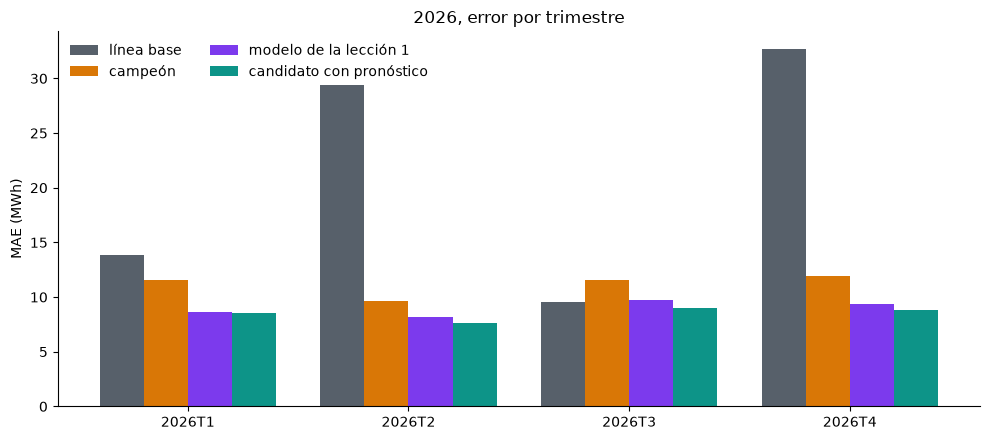

,línea base,campeón,modelo de la lección 1,candidato con pronóstico
2026T1,13.89,11.59,8.62,8.56
2026T2,29.40,9.67,8.15,7.66
2026T3,9.53,11.59,9.76,8.98
2026T4,32.67,11.90,9.41,8.81


In [31]:
trimestres = ["2026T1", "2026T2", "2026T3", "2026T4"]
tabla_q = pd.DataFrame(
    {
        "línea base": e_base_2026.groupby(e_base_2026.index.quarter).mean(),
        "campeón": e_campeon.groupby(e_campeon.index.quarter).mean(),
        "modelo de la lección 1": e_leccion_1.groupby(e_leccion_1.index.quarter).mean(),
        "candidato con pronóstico": e_candidato.groupby(e_candidato.index.quarter).mean(),
    }
)
tabla_q.index = trimestres

colores = [GRIS, AMBAR, VIOLETA, TURQUESA]
fig, ax = plt.subplots(figsize=(10, 4.5))
ancho = 0.2
for k, (nombre, color) in enumerate(zip(tabla_q.columns, colores)):
    ax.bar(np.arange(4) + (k - 1.5) * ancho, tabla_q[nombre], ancho, color=color, label=nombre)
ax.set_xticks(np.arange(4), trimestres)
ax.set_ylabel("MAE (MWh)")
ax.set_title("2026, error por trimestre")
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

tabla_q.round(2)

El segundo candidato tiene un MAE de 8,50 en 2026 y gana en los cuatro trimestres, también en el tercero: 8,98 contra 9,53 de la línea base. La compuerta lo aprueba sin razones en contra.

Hay que leer esto con cuidado: 2026 está aquí como ilustración. Este candidato se armó después de ver los errores de 2026, así que su aprobación no vale como evidencia. En producción la compuerta no conoce el año de uso: se calcula con un backtest de origen móvil sobre la historia, como el de la lección 3.

In [32]:
def error_estandar_por_bloques(diferencia, bloque=7, repeticiones=2000, semilla=0):
    # Error estándar de la media de una serie diaria autocorrelacionada, con bootstrap por bloques de 7 días.
    d = diferencia.to_numpy()
    n = len(d)
    rng = np.random.default_rng(semilla)
    inicios = rng.integers(0, n - bloque + 1, size=(repeticiones, -(-n // bloque)))
    medias = [np.concatenate([d[i:i + bloque] for i in fila])[:n].mean() for fila in inicios]
    return float(np.std(medias))


diferencia = (e_leccion_1 - e_base_2026)["2026-07-01":"2026-09-30"]  # modelo de la lección 1 menos línea base, tercer trimestre
print(f"diferencia de MAE en el tercer trimestre: {diferencia.mean():.2f} MWh, sobre {len(diferencia)} días")
print(f"error estándar (bootstrap por bloques):   {error_estandar_por_bloques(diferencia):.2f} MWh")

diferencia de MAE en el tercer trimestre: 0.22 MWh, sobre 92 días
error estándar (bootstrap por bloques):   1.32 MWh


El rechazo del tercer trimestre pide una lectura cuidadosa. La diferencia entre el modelo de la lección 1 y la línea base es de 0,22 MWh sobre 92 días, y su error estándar, estimado con un bootstrap por bloques de 7 días porque los errores de días seguidos están correlacionados, es de 1,32 MWh: la diferencia es mucho menor que su incertidumbre. Con esos datos no se puede afirmar que el modelo sea peor que la línea base en ese trimestre, ni que sea mejor.

La compuerta de esta lección rechaza igual, porque aplica la regla del contrato tal como está escrita, sin margen. Una compuerta real agrega uno, o compara con una diferencia pareada y su intervalo: rechaza solo si el candidato pierde por más que el ruido, o si el intervalo de la diferencia queda entero del lado de la derrota.

La compuerta de esta lección es un adelanto. En el módulo 2 se le agrega lo que falta para que decida de verdad: los candidatos quedan registrados con sus métricas y el campeón se lee del registro. En el módulo 3 corre como un paso del pipeline, con el backtesting de la lección 3 en vez de un solo año.

## 7. Del notebook al repositorio

Las pruebas que viven en un notebook se pierden con el notebook: nadie las corre al cambiar el código, y el notebook depende de variables que otra celda dejó definidas. Para que protejan algo, tienen que vivir en el repositorio y correr solas en cada cambio. La estructura habitual separa el paquete (`src/`) de las pruebas (`tests/`).

La celda siguiente escribe, en una carpeta temporal, un paquete mínimo con las funciones de las secciones 3 y 4. Los archivos del paquete se arman con el código de las celdas anteriores, para que no haya dos versiones. Las pruebas de `tests/` usan tablas chicas hechas a mano, y no la historia de la planta: un repositorio no depende de descargar datos para probarse.

In [33]:
import inspect
import shutil

REPO = Path("salidas") / "consumo-energia"  # el repositorio de ejemplo; salidas/ no entra a git
shutil.rmtree(REPO, ignore_errors=True)
REPO.mkdir(parents=True)
REPO = REPO.resolve()


def escribir(ruta, texto):
    destino = REPO / ruta
    destino.parent.mkdir(parents=True, exist_ok=True)
    destino.write_text(texto.strip("\n") + "\n", encoding="utf-8")


def fuente(*funciones):
    return "\n\n\n".join(inspect.getsource(f).rstrip() for f in funciones)


constantes = f"COLUMNAS = {COLUMNAS!r}\nRANGOS = {RANGOS!r}\nRAZON_MAXIMA = {RAZON_MAXIMA!r}"

escribir("src/consumo/__init__.py", "# Pronóstico diario del consumo eléctrico de la planta")

escribir(
    "src/consumo/features.py",
    '# Features del pronóstico. Solo usan datos que existen a las 06:00.\n\nimport pandas as pd\n\n\n'
    + fuente(armar_features),
)

escribir(
    "src/consumo/validar.py",
    '# Pruebas de datos: devuelven la lista de problemas, vacía si la tabla está sana.\n\n'
    "import argparse\n\nimport pandas as pd\n\n"
    + constantes
    + "\n\n\n"
    + fuente(problemas_esquema, problemas_rangos, problemas_fechas, problemas_unidades, validar)
    + '''


def main(argv=None):
    # Paso `validar` de un pipeline: termina con código 1 si los datos no pasan.
    parser = argparse.ArgumentParser()
    parser.add_argument("--entrada", required=True, help="CSV con la columna fecha")
    tabla = pd.read_csv(parser.parse_args(argv).entrada, parse_dates=["fecha"], index_col="fecha")
    problemas = validar(tabla)
    for problema in problemas:
        print("FALLA:", problema)
    if not problemas:
        print(f"{len(tabla)} días válidos")
    return 1 if problemas else 0


if __name__ == "__main__":
    raise SystemExit(main())
''',
)

escribir(
    "tests/conftest.py",
    '''
import numpy as np
import pandas as pd
import pytest


@pytest.fixture
def tabla_chica():
    # Cuarenta días desde el lunes 2 de marzo de 2026, con consumo 100, 101, 102, ...
    fechas = pd.date_range("2026-03-02", periods=40, name="fecha")
    rng = np.random.default_rng(0)
    return pd.DataFrame(
        {
            "produccion": 3000 + rng.integers(-100, 100, 40),
            "temperatura_pronostico": 15.0 + rng.normal(0, 2, 40),
            "temperatura": 15.0 + rng.normal(0, 2, 40),
            "consumo": 100.0 + np.arange(40),
        },
        index=fechas,
    )
''',
)

escribir(
    "tests/test_features.py",
    '''
import numpy as np
import pandas as pd

from consumo.features import armar_features


'''
    + fuente(perturbar_desde, problemas_causalidad)
    + '''


def test_rezagos_a_mano(tabla_chica):
    x = armar_features(tabla_chica).loc["2026-03-11"]
    assert x["consumo_ayer"] == 108.0
    assert x["consumo_semana_pasada"] == 102.0
    assert x["dia_semana"] == 2  # miércoles


def test_un_dia_que_falta_no_desplaza_el_rezago(tabla_chica):
    x = armar_features(tabla_chica.drop(pd.Timestamp("2026-03-08")))
    assert np.isnan(x.loc["2026-03-09", "consumo_ayer"])


def test_las_features_son_causales(tabla_chica):
    problemas = problemas_causalidad(armar_features, tabla_chica)
    assert not problemas, problemas
''',
)

escribir(
    "tests/test_validar.py",
    '''
import pandas as pd

from consumo.validar import validar


def test_una_tabla_sana_pasa(tabla_chica):
    assert validar(tabla_chica) == []


def test_el_consumo_en_kwh_se_rechaza(tabla_chica):
    tabla = tabla_chica.copy()
    tabla.loc["2026-03-20":, "consumo"] *= 1000
    problemas = validar(tabla)
    assert any("fuera de" in p for p in problemas)
    assert any("pasa de" in p for p in problemas)


def test_un_dia_que_falta_se_rechaza(tabla_chica):
    problemas = validar(tabla_chica.drop(pd.Timestamp("2026-03-10")))
    assert problemas == ["faltan 1 día(s) antes del 2026-03-11"]


def test_una_columna_que_falta_se_rechaza(tabla_chica):
    assert validar(tabla_chica.drop(columns="consumo")) == ["faltan columnas: ['consumo']"]
''',
)

escribir(
    "pyproject.toml",
    '''
[tool.pytest.ini_options]
pythonpath = ["src"]
testpaths = ["tests"]
addopts = "-q"
''',
)
escribir("requirements.txt", "\n".join(f"{p}=={version(p)}" for p in ("numpy", "pandas", "scikit-learn", "pytest")))
print((REPO / "requirements.txt").read_text())

for ruta in sorted(REPO.rglob("*")):
    if ruta.is_file():
        print(ruta.relative_to(REPO).as_posix())

numpy==2.4.6
pandas==3.1.0
scikit-learn==1.9.1
pytest==9.2.0

pyproject.toml
requirements.txt
src/consumo/__init__.py
src/consumo/features.py
src/consumo/validar.py
tests/conftest.py
tests/test_features.py
tests/test_validar.py


`pyproject.toml` le dice a pytest dónde está el paquete (`pythonpath = ["src"]`) y dónde están las pruebas. Con eso, una sola orden las corre. Es la orden que usará la integración continua:

In [34]:
import os
import subprocess
import sys


def correr(*orden):
    # Ejecuta una orden dentro del repositorio de ejemplo y muestra su salida.
    entorno = {**os.environ, "PYTHONUTF8": "1", "PYTHONPATH": str(REPO / "src"), "PYTHONDONTWRITEBYTECODE": "1", "PY_COLORS": "0"}
    resultado = subprocess.run(orden, cwd=REPO, env=entorno, capture_output=True, text=True, encoding="utf-8")
    print(resultado.stdout.strip())
    print(resultado.stderr.strip())
    return resultado.returncode


_ = correr(sys.executable, "-m", "pytest", "-p", "no:cacheprovider")

.......                                                                  [100%]
7 passed in 0.29s



Pasan las siete pruebas, cuatro de datos y tres de features, sobre tablas chicas. Una prueba protege mientras pueda fallar. Se reintroduce en el paquete la fuga de la sección 4, la temperatura real en lugar del pronóstico, como si alguien la hubiera escrito en un PR:

In [35]:
archivo = REPO / "src" / "consumo" / "features.py"
correcto = archivo.read_text(encoding="utf-8")
roto = correcto.replace('"temperatura_pronostico": t["temperatura_pronostico"]', '"temperatura_pronostico": t["temperatura"]')
assert roto != correcto

_ = archivo.write_text(roto, encoding="utf-8")
codigo = correr(sys.executable, "-m", "pytest", "-p", "no:cacheprovider", "--tb=no", "-rf")
print("código de salida:", codigo)
_ = archivo.write_text(correcto, encoding="utf-8")

..F....                                                                  [100%]
=========================== short test summary info ===========================
FAILED tests/test_features.py::test_las_features_son_causales - AssertionErro...
1 failed, 6 passed in 0.20s

código de salida: 1


Falla una sola prueba, la de causalidad, y el código de salida es 1, que es lo que una integración continua entiende por rechazo: el PR no se puede mezclar. Las pruebas de ejemplo no ven la fuga, porque con la tabla chica los rezagos siguen bien; solo la prueba de propiedad la atrapa. Con el archivo restaurado, la suite vuelve a pasar.

El mismo módulo sirve de paso `validar` en un pipeline: `python -m consumo.validar` termina con código 0 si los datos pasan y con código 1 si no. Un trabajo que termina con error detiene a los que dependen de él, que es lo que pide el caso del curso: no se publica un pronóstico construido con datos rotos.

In [36]:
serie[:"2026-03-01"].to_csv(REPO / "datos_buenos.csv")
con_kwh[:"2026-03-01"].to_csv(REPO / "datos_con_kwh.csv")

for archivo in ("datos_buenos.csv", "datos_con_kwh.csv"):
    print(f"$ python -m consumo.validar --entrada {archivo}")
    codigo = correr(sys.executable, "-m", "consumo.validar", "--entrada", archivo)
    print("código de salida:", codigo, "\n")

$ python -m consumo.validar --entrada datos_buenos.csv
1521 días válidos

código de salida: 0 

$ python -m consumo.validar --entrada datos_con_kwh.csv
FALLA: consumo: 20 valores fuera de [0, 450] (desde el 2026-02-10: 314700)
FALLA: consumo: pasa de 294.6 a 314700.0 el 2026-02-10

código de salida: 1 



### 7.1 El módulo, completo

La lección 1 terminó con este diagrama, donde cada paso del pipeline decía qué lección lo construía. Ahora todas existen:

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/notebook-y-pipeline.svg" alt="A la izquierda, un notebook con seis celdas cuyos números de ejecución están fuera de orden: 3, 7, 5, 8, 6 y 9. A la derecha, un pipeline: datos v3, validar (lección 5), features (lección 4), entrenar (lección 2), evaluar (lección 3) y el modelo v7 registrado (módulo 2). La animación marca las celdas 7 y 5, que corrieron fuera de orden, y después recorre el pipeline paso a paso" width="760">

Cada condición de la Definición 1.6 tiene ahora una falla que se vio, una herramienta que la resuelve y una prueba que la vigila:

| Condición | Falla de la lección 1 | Lección | Qué la vigila |
|---|---|---|---|
| Reproducible | 5.1 No se repite | 2 | Dos corridas con la misma configuración dan el mismo modelo |
| Evaluado como se usa | 5.2 La partición al azar mira el futuro | 3 | El backtesting de origen móvil y el conjunto de prueba temporal |
| Una sola transformación | 5.3 Lo que no existe a las 06:00 | 4 | Causalidad de las features y mismas columnas con un solo día |
| Probado | 5.4 Nada lo prueba | 5 | Pruebas de datos, de features y de modelo, y la compuerta |
| Registrado y observado | El error de 2026 se supo recién al final | Módulos 2 y 6 | El registro de modelos y el monitoreo |

Las cuatro primeras filas son código que corre en un notebook, sin suscripción y en CPU. La quinta necesita un servicio que guarde el historial de los modelos y mida el error cada día, y para eso sirven los módulos siguientes.

In [37]:
import shutil

shutil.rmtree(REPO, ignore_errors=True)  # borra el repositorio de ejemplo
print("repositorio de ejemplo borrado:", not REPO.exists())

repositorio de ejemplo borrado: True


## 8. En Azure

Dos piezas de Azure ML y GitHub cumplen en producción lo que hizo esta lección. La primera protege el código y corre en cada cambio. La segunda protege los datos y corre en cada ejecución del pipeline.

**Pruebas en cada pull request.** Un flujo de trabajo de GitHub Actions corre `pytest` cuando se abre o se actualiza un PR. No necesita credenciales de Azure, porque las pruebas no tocan el workspace. En el módulo 5 se completa con el lint y el entrenamiento corto sobre una muestra, y se exige que pase antes de hacer merge.

```yaml
# .github/workflows/pruebas.yml
name: pruebas
on:
  pull_request:
    branches: [main]
jobs:
  pytest:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v7
      - uses: actions/setup-python@v7
        with:
          python-version: "3.11"
          cache: pip
      - run: pip install -r requirements.txt
      - run: python -m pytest
```

**El paso `validar` del pipeline de entrenamiento.** En el pipeline job que entrena el modelo, `validar` es el primer paso y las features dependen de su salida. Cada paso es un *component* de Azure ML que ejecuta un comando, y el paso `validar` ejecuta el módulo de la sección 7.

```yaml
# components/validar.yml
$schema: https://azuremlschemas.azureedge.net/latest/commandComponent.schema.json
name: validar
version: 1
type: command
inputs:
  datos:
    type: uri_file
outputs:
  datos_validos:
    type: uri_folder
code: ../src
environment: azureml:forecast-env:1   # el environment de la lección 2, con versión fija
command: >-
  python -m consumo.validar --entrada ${{inputs.datos}}
  && cp ${{inputs.datos}} ${{outputs.datos_validos}}/
```

```yaml
# pipelines/entrenamiento-consumo.yml (fragmento)
jobs:
  validar:
    type: command
    component: ../components/validar.yml
    inputs:
      datos: ${{parent.inputs.historico}}
  features:
    type: command
    component: ../components/features.yml
    inputs:
      datos: ${{parent.jobs.validar.outputs.datos_validos}}
```

Si `validar` termina con código 1, el trabajo falla y `features` no corre: el pipeline se detiene y avisa, que es lo que pide el contrato del pronóstico. La compuerta de la sección 6 es el último paso del mismo pipeline, y decide si el modelo se registra.

## Ejercicios

**Ejercicio 1 (la parada de mantención no es una anomalía).** Un colega propone una prueba de datos más: el consumo no cambia más de 60 MWh entre dos días seguidos. Contar cuántos días de `historia` marca. ¿Son datos rotos? Corregir la prueba para que no marque esos días y siga marcando un salto sin explicación.

*Pista:* la Definición 1.3 dice que cada tonelada consume 0,07 MWh. Un salto de consumo que acompaña a un salto de producción tiene explicación.

<details>
<summary>Solución</summary>

```python
saltos = historia["consumo"].diff().abs()
marcados = historia.index[saltos > 60]
print("días marcados por la prueba ingenua:", len(marcados))
print(marcados.strftime("%Y-%m-%d").tolist())

residuo = historia["consumo"] - 0.07 * historia["produccion"]  # lo que la producción no explica
print(f"mayor salto del residuo en la historia: {residuo.diff().abs().max():.1f} MWh")

dato_roto = historia.copy()
dato_roto.iloc[500, dato_roto.columns.get_loc("consumo")] += 100  # un salto sin explicación
residuo_roto = dato_roto["consumo"] - 0.07 * dato_roto["produccion"]
print("días marcados con el residuo (límite 40 MWh):", residuo_roto.diff().abs().gt(40).sum())
print(dato_roto.index[residuo_roto.diff().abs() > 40].strftime("%Y-%m-%d").tolist())
```

La prueba ingenua marca 64 días. Ninguno es un dato roto: son el inicio o el fin de una parada, un domingo (se produce menos) o el lunes que le sigue. Una prueba que se equivoca 64 veces en cuatro años se desactiva, y con ella se pierde la capacidad de atrapar algo real.

Un salto de consumo que acompaña a un salto de producción tiene explicación; uno que no, no. Se resta del consumo lo que explica la producción, 0,07 MWh por tonelada, y el salto se mide sobre lo que queda. En la historia el mayor salto del residuo es 30,9 MWh, así que el límite de 40 no marca ningún día. Un salto inventado de 100 MWh el 16 de mayo de 2023 sí se marca, ese día y el siguiente, cuando el consumo vuelve a su nivel. El límite de 40 sale de mirar la historia con margen, como el de la sección 3, y se revisa igual.

</details>

**Ejercicio 2 (monotonía garantizada).** La sección 5.1 tolera caídas porque el bosque no es monótono. scikit-learn permite pedirle monotonía al entrenar con el parámetro `monotonic_cst`. Entrenar el bosque con la producción restringida a ser no decreciente, repetir la prueba con tolerancia 0 y comparar el MAE de 2025 con el del bosque libre.

*Pista:* `monotonic_cst` es una lista con un valor por columna: 1 para no decreciente, 0 para sin restricción.

<details>
<summary>Solución</summary>

```python
X_ent = X_todo[ent].dropna()
monotono = RandomForestRegressor(
    n_estimators=200, random_state=0, n_jobs=-1, monotonic_cst=[0, 1, 0, 0, 0]  # la producción es la columna 1
).fit(X_ent, y_todo[X_ent.index])

caidas_mono = [caida_maxima(c) for c in curvas_produccion(monotono, X_2025)]
print(f"caída máxima en los 40 días: {max(caidas_mono):.2f} MWh")
print(f"MAE 2025 del bosque libre:     {error_abs(campeon, X_2025, y_2025).mean():.2f}")
print(f"MAE 2025 del bosque monótono:  {error_abs(monotono, X_2025, y_2025).mean():.2f}")
```

La caída máxima baja a 0 en los 40 días, y el MAE de 2025 sube de 8,01 a 8,07: la restricción cuesta 0,06 MWh. Es un buen trato cuando la monotonía es un requisito, y por eso la tolerancia de la sección 5.1 es una decisión: se paga precisión por garantía, o se acepta una caída pequeña. `monotonic_cst` en `RandomForestRegressor` pide scikit-learn 1.4 o más nuevo y no admite valores nulos.

</details>

**Ejercicio 3 (la compuerta por trimestre es más exigente).** Sea $E_q(f)$ el MAE de un pronóstico $f$ en el trimestre $q$ y $n_q$ el número de días de ese trimestre. Demostrar que si el candidato $c$ le gana a la línea base $b$ en cada trimestre, también le gana en el año. Dar un ejemplo donde el año aprueba y el trimestre rechaza.

*Pista:* el MAE del año es un promedio ponderado de los MAE de los trimestres.

<details>
<summary>Solución</summary>

```python
def gana_en_el_anio(candidato, linea_base):
    return candidato.mean() < linea_base.mean()


def gana_en_cada_trimestre(candidato, linea_base):
    por_q = lambda e: e.groupby(e.index.to_period("Q")).mean()
    return bool((por_q(candidato) < por_q(linea_base)).all())


a_mano = por_trimestre(5, 5, 11, 5)  # contra una línea base de 10 en cada trimestre
print("a mano:         año", gana_en_el_anio(a_mano, BASE), "| trimestres", gana_en_cada_trimestre(a_mano, BASE), f"| MAE del año {a_mano.mean():.2f}")
print("lección 1:      año", gana_en_el_anio(e_leccion_1, e_base_2026), "| trimestres", gana_en_cada_trimestre(e_leccion_1, e_base_2026))
print("con pronóstico: año", gana_en_el_anio(e_candidato, e_base_2026), "| trimestres", gana_en_cada_trimestre(e_candidato, e_base_2026))
```

*Demostración.* Sea $n = \sum_q n_q$. El MAE del año es $E(f) = \sum_q \frac{n_q}{n} E_q(f)$, un promedio con pesos positivos que suman 1. Si $E_q(c) < E_q(b)$ para todo $q$,

$$E(c) = \sum_q \frac{n_q}{n} E_q(c) < \sum_q \frac{n_q}{n} E_q(b) = E(b). \quad \square$$

La compuerta por trimestre implica la anual, y la recíproca es falsa: un promedio puede ganar aunque un término pierda. El ejemplo a mano es un candidato con error 5, 5, 11 y 5 contra una línea base de 10 en cada trimestre: el año aprueba, con MAE 6,51, y el tercer trimestre rechaza. Con datos reales es el modelo de la lección 1: gana en el año y pierde en el tercer trimestre. El candidato con el pronóstico de temperatura gana en los dos.

La demostración no usa que los segmentos sean trimestres: vale para cualquier partición de los días, por mes, por día de la semana o por nivel de consumo. Cuanto más fina la partición, más exigente la compuerta, y también más expuesta al azar: un segmento con pocos días puede rechazar a un buen candidato por mala suerte.

</details>

**Ejercicio 4 (rechazar la entrada rota).** Las pruebas de datos protegen la tabla de entrenamiento. Falta proteger la entrada del día: si el consumo de ayer llega en kWh, el modelo de la lección 1 pronosticaba sin avisar. Escribir una función `pronosticar(modelo, x)` que rechace con un error las entradas fuera de los rangos físicos, y las dos pruebas que la acompañan: una que acepta un día normal y otra que rechaza el consumo en kWh del 10 de febrero de 2026.

*Pista:* `pytest.raises(ValueError, match="consumo_ayer")` espera que el código dentro del bloque falle con ese error.

<details>
<summary>Solución</summary>

```python
%%ipytest -q
LIMITES = {
    "produccion": RANGOS["produccion"],
    "temperatura_pronostico": RANGOS["temperatura_pronostico"],
    "consumo_ayer": RANGOS["consumo"],
    "consumo_semana_pasada": RANGOS["consumo"],
}


def pronosticar(modelo, x):
    for columna, (minimo, maximo) in LIMITES.items():
        if not x[columna].between(minimo, maximo).all():
            raise ValueError(f"{columna} fuera de [{minimo:g}, {maximo:g}]: {x[columna].iloc[0]:g}")
    return modelo.predict(x)


def test_acepta_un_dia_normal():
    assert pronosticar(campeon, X_2026.iloc[[40]]).shape == (1,)  # el 10 de febrero de 2026


def test_rechaza_el_consumo_en_kwh():
    x = X_2026.iloc[[40]].assign(consumo_ayer=lambda d: d["consumo_ayer"] * 1000)
    with pytest.raises(ValueError, match="consumo_ayer"):
        pronosticar(campeon, x)
```

La función rechaza antes de pronosticar, con un mensaje que nombra la columna, y las dos pruebas pasan. En un endpoint es la validación de la entrada. La *signature* de MLflow, que llega en el módulo 2, comprueba columnas y tipos, y los rangos físicos siguen siendo trabajo de una función como esta. La comprobación `between` también rechaza los nulos, que un bosque aceptaría sin avisar (sección 4.1).

</details>

El módulo 1 cierra aquí. Empezó con un modelo que prometía 6,1 MWh y entregaba 9,0 sin avisar. Termina con un pipeline en el que los datos se validan antes de usarse, las features son causales y se calculan con una sola función, el modelo se evalúa con el futuro y no con el azar, y un candidato solo pasa si una compuerta lo aprueba por trimestre. Nada de eso es específico de la planta: son las mismas pruebas de cualquier sistema que pronostica todos los días.

**Siguiente:** el módulo 2 registra cada entrenamiento con MLflow y decide con una compuerta qué modelo pasa a producción.